# DAMICORE aplicado a EEG — Controle × CCL (MCI) × Alzheimer (AD)

**Etapa 1 deste notebook**
1. Inventário do dataset (Cejnek et al., 2021) e preparação/harmonização dos sinais.
2. DAMICORE **por canal**: cada paciente vira um objeto (arquivo); NCD → Neighbor Joining → FastGreedy.
   O cluster atribuído a cada paciente em cada canal é a **discretização** do canal.
3. Filogramas por canal (coloridos pelo diagnóstico, que *não* entra no DAMICORE).
4. **Tabelas de probabilidade** construídas a partir da discretização, prontas para a etapa 2
   (aplicar o DAMICORE novamente sobre a tabela).

Fluxo (slides *AED de Propósito Geral*, Delbem): dados crus → DAMICORE → grupos → tabela de probabilidades → modelo.

## Ambiente e dados

O dataset original é público ([figshare, doi 10.6084/m9.figshare.5450293](https://doi.org/10.6084/m9.figshare.5450293), licença CC BY 4.0):
um `dataset.zip` de ~306 MB com `AD/`, `CONTROL/`, `MCI/` e `readme.txt`. O notebook espera os dados em `<projeto>/dataset/dataset/`
e faz toda a preparação dos sinais a partir dos arquivos originais.

- **Local:** baixe e extraia o zip em `dataset/dataset/` (ou descomente a linha de download abaixo).
- **Google Colab:** descomente as linhas da célula abaixo (instalação, clone do repositório e download dos dados). A primeira execução completa leva ~15 min.

In [1]:
# ---- Google Colab: descomente para instalar, clonar o projeto e baixar os dados originais ----
# !pip install -q damicore==0.3.0
# !git clone -q https://github.com/rmanosso/damicore-eeg.git
# %cd damicore-eeg

# ---- Dados originais (local ou Colab): baixa e extrai em dataset/dataset/ ----
# !mkdir -p dataset/dataset && wget -q -O dataset/dataset.zip https://ndownloader.figshare.com/files/9423433 && unzip -q -o dataset/dataset.zip -d dataset/dataset && rm dataset/dataset.zip

# ---- Alternativa no Colab: dados já salvos no seu Google Drive ----
# from google.colab import drive; drive.mount('/content/drive')
# CAMINHO_DADOS = '/content/drive/MyDrive/<pasta>/dataset'   # pasta que contém AD/, CONTROL/, MCI/ e readme.txt

## 0. Configuração

Parâmetros escolhidos a partir da inspeção do dataset (ver seção 1):

| Parâmetro | Valor | Motivo |
|---|---|---|
| `FS_ALVO` | 128 Hz | metade dos registros já está em 128 Hz; o paper também reamostra 256 → 128 |
| `BANDA_HZ` | 4,5–40 Hz | os registros de 256 Hz vêm com passa-alta de ~4 Hz (sem delta) e os AD/MCI de 128 Hz com ~2 Hz; os controles têm 0,5 Hz. Sem banda comum, o DAMICORE separa **pelo filtro do equipamento** e não pela doença. Use `None` para desligar e comparar |
| `DURACAO_S` | 48 s | maior janela comum a todos os pacientes válidos (o mais curto, AD46, tem 48,9 s) e mantém cada par de objetos < 32 KB, a janela do zlib |
| `N_NIVEIS` | 8 | z-score por canal → corte em ±4σ → 8 níveis (1 byte/amostra). Testado 4–256 no T6: níveis grosseiros dão mais contraste de NCD; 256 níveis deixam o NCD ≈ 1 para todos os pares |

In [2]:
from pathlib import Path
import json, re, shutil, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.signal import resample_poly, butter, sosfiltfilt, welch
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
warnings.filterwarnings('ignore', message='IProgress not found')   # aviso do tqdm sem ipywidgets
from damicore import run, ExecutionConfig, OutputDirectoryConflictError, TreeFormatError

def eh_pasta_dados(p):
    return (p / 'readme.txt').is_file() and all((p / g).is_dir() for g in ('AD', 'CONTROL', 'MCI'))

# raiz do projeto = pasta que contém 'dataset/' (o notebook pode ser aberto de scripts/ ou da raiz)
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dataset').is_dir()), Path.cwd())
if 'CAMINHO_DADOS' in globals():                  # definido na célula do Google Drive
    DADOS = Path(CAMINHO_DADOS)
else:                                             # procura AD/, CONTROL/, MCI/ e readme.txt dentro de dataset/
    DADOS = next((p for p in [RAIZ / 'dataset' / 'dataset', RAIZ / 'dataset', *sorted((RAIZ / 'dataset').glob('**/'))]
                  if eh_pasta_dados(p)), None)
if DADOS is None or not eh_pasta_dados(DADOS):
    raise FileNotFoundError('Dados não encontrados: extraia o dataset.zip em <projeto>/dataset/dataset/ (ver célula "Ambiente e dados").')
SAIDA = RAIZ / 'resultados'

FS_ALVO = 128
BANDA_HZ = (4.5, 40.0)      # None = sem filtro (apenas reamostragem)
DURACAO_S = 48
N_NIVEIS = 8
CLIP_SIGMA = 4.0
N_AMOSTRAS = DURACAO_S * FS_ALVO

# Ordem 10-20 com 19 canais (Tabelas 3-5 do paper). Os .mat não trazem nomes de canais:
# a ordem é uma suposição, consistente com a estrutura de correlação (O1-O2, P3-Pz-P4 vizinhos muito correlacionados).
CANAIS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T3', 'C3', 'Cz',
          'C4', 'T4', 'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2']

# Cores fixas por grupo (identidade, nunca reatribuídas)
CORES = {'CONTROL': '#2a78d6', 'MCI': '#eb6834', 'AD': '#1baf7a'}
ORDEM_GRUPOS = ['CONTROL', 'MCI', 'AD']

SAIDA.mkdir(exist_ok=True)
print('Projeto:', RAIZ)
print('Dados:  ', DADOS)

Projeto: C:\DAMICORE
Dados:   C:\DAMICORE\dataset\dataset


## 1. Inventário do dataset

Formatos encontrados:
- **AD / MCI**: uma pasta por paciente com vários `.mat` (variável `export`, `amostras × canais`). São segmentos já limpos de artefatos.
  Alguns arquivos têm 17, 18 ou 20 colunas → descartados (não dá para mapear os canais). **AD33 e AD44 estão vazios.**
- **CONTROL**: 100 arquivos `*fir.mat` (variável `segmenty`, `canais × amostras`, 22 ou 25 linhas — as 19 primeiras são o EEG, o resto é zero ou canal auxiliar)
  + `normal1` e `normal2` no formato `export` → 102 controles, como no paper.
- Frequência (readme): AD1–34 e MCI1–4 a 256 Hz (aparelho Walter); AD35–59, MCI5–7, normal1–2 e `fir` a 128 Hz.
- Escalas diferentes: `fir` em µV (desvio ~35), `export` em outra unidade (desvio ~0,02) → z-score por canal é obrigatório.

In [3]:
def ler_readme(caminho):
    linhas = []
    for l in caminho.read_text(encoding='latin-1').splitlines():
        p = l.split('\t')
        if len(p) == 8 and p[7].strip() and p[0].strip().isdigit():
            linhas.append(dict(paciente=p[7].strip(), atencao=int(p[0]), memoria=int(p[1]), fluencia=int(p[2]),
                               linguagem=int(p[3]), visuoespacial=int(p[4]), escore_total=int(p[5]), fs_readme=int(p[6])))
    return pd.DataFrame(linhas).set_index('paciente')

escores = ler_readme(DADOS / 'readme.txt')

def inventario():
    reg, descartes = [], []
    for grupo in ['AD', 'MCI']:
        for pasta in sorted((DADOS / grupo).iterdir(), key=lambda p: int(p.name[len(grupo):])):
            fs = int(escores.loc[pasta.name, 'fs_readme'])
            arqs = []
            for f in sorted(pasta.glob('*.mat'), key=lambda p: int(p.stem)):
                n_ch = sio.loadmat(f, variable_names=['export'])['export'].shape[1]
                (arqs if n_ch == 19 else descartes).append(f if n_ch == 19 else (pasta.name, f.name, f'{n_ch} canais'))
            if not arqs:
                descartes.append((pasta.name, '-', 'pasta sem arquivos válidos'))
                continue
            reg.append(dict(paciente=pasta.name, grupo=grupo, formato='export', fs=fs,
                            equipamento='Walter-256Hz' if fs == 256 else 'Alien-128Hz', arquivos=arqs))
    for f in sorted((DADOS / 'CONTROL').glob('*fir.mat')):
        reg.append(dict(paciente=f.stem, grupo='CONTROL', formato='fir', fs=128, equipamento='Alien-128Hz-fir', arquivos=[f]))
    for nome in ['normal1', 'normal2']:
        arqs = sorted((DADOS / 'CONTROL' / nome).glob('*.mat'), key=lambda p: int(p.stem))
        reg.append(dict(paciente=nome, grupo='CONTROL', formato='export', fs=128, equipamento='Alien-128Hz', arquivos=arqs))
    meta = pd.DataFrame(reg).set_index('paciente')
    return meta.join(escores[['escore_total']]), pd.DataFrame(descartes, columns=['paciente', 'arquivo', 'motivo'])

meta, descartes = inventario()
print(meta.groupby(['grupo', 'equipamento']).size().unstack(fill_value=0))
print(f'\nTotal de pacientes válidos: {len(meta)}')
print('\nDescartes:'); print(descartes.to_string(index=False))

equipamento  Alien-128Hz  Alien-128Hz-fir  Walter-256Hz
grupo                                                  
AD                    24                0            33
CONTROL                2              100             0
MCI                    3                0             4

Total de pacientes válidos: 166

Descartes:
paciente arquivo                     motivo
     AD1   3.mat                  18 canais
    AD17   2.mat                  17 canais
    AD21   5.mat                  18 canais
    AD33       - pasta sem arquivos válidos
    AD35   1.mat                  18 canais
    AD35   2.mat                  18 canais
    AD35   3.mat                  18 canais
    AD35   6.mat                  18 canais
    AD40   1.mat                  20 canais
    AD44       - pasta sem arquivos válidos
    AD46   1.mat                  20 canais
    AD53   1.mat                  20 canais


## 2. Preparação dos sinais (harmonização mínima)

Para cada paciente e canal:
1. lê cada segmento (`.mat`) separadamente; reamostra 256 → 128 Hz (`resample_poly`, com anti-aliasing);
2. aplica o passa-banda comum (Butterworth ordem 4, fase zero) **por segmento**, para não filtrar através das emendas;
3. concatena os segmentos e recorta uma janela central de `DURACAO_S`;
4. z-score do canal, corte em ±`CLIP_SIGMA`σ e quantização uniforme em `N_NIVEIS` → um byte por amostra.

Não há remoção de artefatos, ICA, re-referência, nem extração de características: o DAMICORE recebe o sinal "cru" harmonizado.

In [4]:
SOS = butter(4, BANDA_HZ, btype='band', fs=FS_ALVO, output='sos') if BANDA_HZ else None

def ler_segmentos(linha):
    # Lista de matrizes (amostras x 19) na frequência original.
    if linha.formato == 'fir':
        return [sio.loadmat(linha.arquivos[0])['segmenty'][:19].T.astype(np.float64)]
    return [sio.loadmat(f)['export'].astype(np.float64) for f in linha.arquivos]

def preparar(linha):
    # Sinal harmonizado (N_AMOSTRAS x 19) em float, antes da quantização.
    partes = []
    for x in ler_segmentos(linha):
        if linha.fs != FS_ALVO:
            x = resample_poly(x, FS_ALVO, linha.fs, axis=0)
        if SOS is not None and len(x) > 3 * 27:      # sosfiltfilt precisa de segmento > padlen
            x = sosfiltfilt(SOS, x, axis=0)
        partes.append(x)
    x = np.concatenate(partes)
    if len(x) < N_AMOSTRAS:
        raise ValueError(f'{linha.name}: {len(x)/FS_ALVO:.1f}s < {DURACAO_S}s')
    ini = (len(x) - N_AMOSTRAS) // 2
    return x[ini:ini + N_AMOSTRAS]

def quantizar(x):
    # z-score por canal -> clip ±CLIP_SIGMA -> inteiros 0..N_NIVEIS-1 (uint8)
    z = (x - x.mean(0)) / np.where(x.std(0) > 0, x.std(0), 1.0)
    z = np.clip(z, -CLIP_SIGMA, CLIP_SIGMA)
    return np.round((z + CLIP_SIGMA) / (2 * CLIP_SIGMA) * (N_NIVEIS - 1)).astype(np.uint8)

sinais, falhas = {}, []
for pid, linha in meta.iterrows():
    try:
        sinais[pid] = preparar(linha)
    except ValueError as e:
        falhas.append(str(e))
meta = meta.loc[list(sinais)]
print(f'{len(sinais)} pacientes preparados; excluídos por duração: {falhas or "nenhum"}')

166 pacientes preparados; excluídos por duração: nenhum


### 2.1 Verificação: espectro médio por grupo × equipamento

Antes/depois da harmonização. O objetivo é que as curvas **não** difiram por equipamento dentro da banda usada —
se diferirem, os grupos do DAMICORE vão refletir o aparelho.

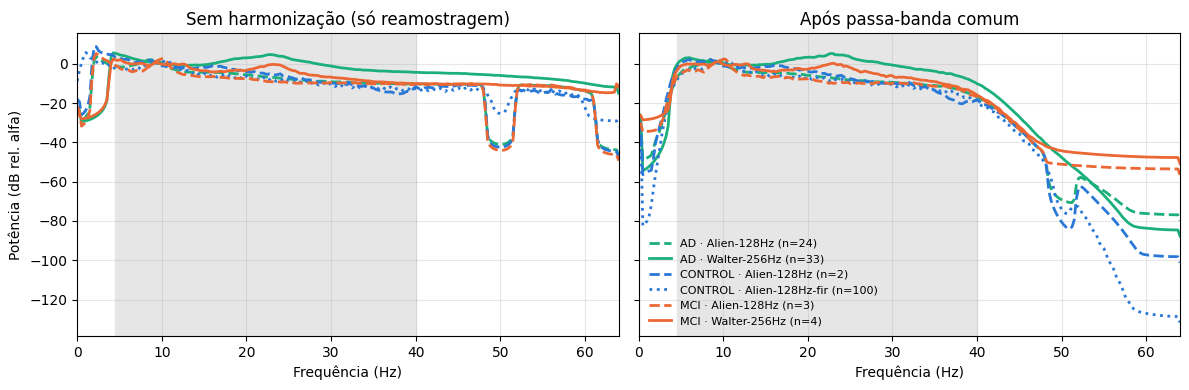

In [5]:
def psd_rel(x):
    f, P = welch(x, fs=FS_ALVO, nperseg=512, axis=0)
    P = P.mean(1)
    return f, 10 * np.log10(P / P[(f >= 8) & (f <= 13)].mean())   # dB relativo à banda alfa

def bruto(linha):
    x = np.concatenate([resample_poly(s, FS_ALVO, linha.fs, axis=0) if linha.fs != FS_ALVO else s
                        for s in ler_segmentos(linha)])
    return x

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
estilos = {'Walter-256Hz': '-', 'Alien-128Hz': '--', 'Alien-128Hz-fir': ':'}
for ax, titulo, fonte in [(eixos[0], 'Sem harmonização (só reamostragem)', 'bruto'), (eixos[1], 'Após passa-banda comum', 'prep')]:
    for (g, eq), sub in meta.groupby(['grupo', 'equipamento']):
        curvas = [psd_rel(bruto(meta.loc[p]) if fonte == 'bruto' else sinais[p]) for p in sub.index[:15]]
        f = curvas[0][0]
        ax.plot(f, np.mean([c[1] for c in curvas], 0), estilos[eq], color=CORES[g], lw=2, label=f'{g} · {eq} (n={len(sub)})')
    if BANDA_HZ:
        ax.axvspan(*BANDA_HZ, color='0.9', zorder=0)
    ax.set_title(titulo); ax.set_xlabel('Frequência (Hz)'); ax.set_xlim(0, 64); ax.grid(alpha=.3)
eixos[0].set_ylabel('Potência (dB rel. alfa)'); eixos[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(SAIDA / 'psd_harmonizacao.png', dpi=130); plt.show()

## 3. Objetos do DAMICORE

Um diretório por canal, com um arquivo binário por paciente (`<grupo>__<paciente>.bin`, 6144 bytes).
O diagnóstico vai no **nome** só para facilitar a leitura do filograma; o DAMICORE usa apenas os bytes.

In [6]:
DIR_OBJ = SAIDA / 'objetos'
if DIR_OBJ.exists():
    shutil.rmtree(DIR_OBJ)                       # regenera sempre: os parâmetros podem ter mudado
canais_planos = []                               # eletrodo morto: o objeto seria constante e distorceria o NCD
for i, canal in enumerate(CANAIS):
    d = DIR_OBJ / canal
    d.mkdir(parents=True)
    for pid, x in sinais.items():
        if x[:, i].std() == 0:
            canais_planos.append((pid, canal)); continue
        (d / f"{meta.loc[pid, 'grupo']}__{pid}.bin").write_bytes(quantizar(x)[:, i].tobytes())
print(f'{len(CANAIS)} canais × {len(sinais)} objetos em {DIR_OBJ}')
print('Canais planos (fora da análise daquele canal):', canais_planos or 'nenhum')

19 canais × 166 objetos em C:\DAMICORE\resultados\objetos
Canais planos (fora da análise daquele canal): [('26887fir', 'Cz'), ('7147fir', 'Cz')]


## 4. DAMICORE por canal (discretização)

`run(..., source_kind='files')`: NCD exato (zlib) → Neighbor Joining → FastGreedy, que escolhe sozinho o número de grupos (`num_clusters=None`).
Cada execução fica em `resultados/damicore/<TAG>/<canal>/` (matriz de distâncias, `tree.nwk`, `membership.csv`, `report.json`).
Se o diretório já tiver uma execução compatível, ela é reaproveitada.

In [7]:
# uma pasta por combinação de parâmetros de preparação -> mudar um parâmetro não colide com execuções antigas
TAG = f"fs{FS_ALVO}_b{'-'.join(map(str, BANDA_HZ)) if BANDA_HZ else 'nao'}_d{DURACAO_S}_n{N_NIVEIS}"
DIR_DMC = SAIDA / 'damicore' / TAG
NUM_CLUSTERS = 2          # None = FastGreedy decide; ou fixe 2, 3, ... para testar a hipótese de k grupos

def pid_de(rotulo):          # 'AD__AD12.bin' -> 'AD12'
    return rotulo.removesuffix('.bin').split('__', 1)[1]

membros, arvores, relatorios = {}, {}, []
for canal in CANAIS:
    sufixo = '' if NUM_CLUSTERS is None else f'_k{NUM_CLUSTERS}'
    destino = DIR_DMC / f'{canal}{sufixo}'
    args = dict(source_kind='files', num_clusters=NUM_CLUSTERS, output_dir=destino,
                progress=False, execution=ExecutionConfig(workers='auto'))
    try:
        r = run(DIR_OBJ / canal, **args)          # reaproveita se a execução já existe com os mesmos objetos
    except OutputDirectoryConflictError:          # objetos mudaram: refaz
        shutil.rmtree(destino); r = run(DIR_OBJ / canal, **args)
    membros[canal] = pd.Series(r.membership['cluster'].values, index=r.membership['label'].map(pid_de))
    arvores[canal] = json.loads(r.artifacts.tree_json.read_text())
    relatorios.append(dict(canal=canal, n_clusters=r.report.cluster_count, modularidade=r.report.modularity,
                           ncd_min=r.report.ncd_min, ncd_max=r.report.ncd_max))
    r.close()
    print(f'{canal:>3}: {relatorios[-1]["n_clusters"]} grupos, modularidade {relatorios[-1]["modularidade"]:.3f}')
relatorios = pd.DataFrame(relatorios).set_index('canal')

Fp1: 2 grupos, modularidade 0.440


Fp2: 2 grupos, modularidade 0.418


 F7: 2 grupos, modularidade 0.495


 F3: 2 grupos, modularidade 0.480


 Fz: 2 grupos, modularidade 0.476


...

 Pz: 2 grupos, modularidade 0.471


 P4: 2 grupos, modularidade 0.469


 T6: 2 grupos, modularidade 0.482


 O1: 2 grupos, modularidade 0.496


 O2: 2 grupos, modularidade 0.487


### 4.1 Tabela discretizada (pacientes × canais)

A tabela é salva duas vezes: `tabela_discretizada.csv` (última execução) e `tabela_discretizada_<auto|k2|k3…>.csv`,
que guarda cada valor de `NUM_CLUSTERS` separadamente e é a entrada da etapa 2.

Os números de cluster do FastGreedy são arbitrários. Para que **partições iguais em canais diferentes tenham a mesma codificação**
(importante para a etapa 2, em que o NCD compara colunas), os rótulos são renomeados por ordem de primeira aparição
numa ordem fixa de pacientes. Isso não usa o diagnóstico. Valor `-1` = canal ausente (eletrodo plano) para aquele paciente.

In [8]:
ordem_pac = meta.sort_values(['grupo', 'equipamento']).index   # ordem fixa e reprodutível

def canonizar(s):
    s = s.reindex(ordem_pac)
    mapa = {}
    for c in s.dropna():
        mapa.setdefault(c, len(mapa))
    return s.map(mapa).fillna(-1).astype(int)

discreta = pd.DataFrame({c: canonizar(membros[c]) for c in CANAIS}).loc[ordem_pac]
discreta.index.name = 'paciente'
ROTULO_ETAPA1 = 'auto' if NUM_CLUSTERS is None else f'k{NUM_CLUSTERS}'
discreta.to_csv(SAIDA / 'tabela_discretizada.csv')                       # última execução
discreta.to_csv(SAIDA / f'tabela_discretizada_{ROTULO_ETAPA1}.csv')      # cópia que não é sobrescrita por outro k
print('Discretização salva como', f'tabela_discretizada_{ROTULO_ETAPA1}.csv')
meta.drop(columns='arquivos').loc[ordem_pac].to_csv(SAIDA / 'metadados_pacientes.csv')
discreta.head()

Discretização salva como tabela_discretizada_k2.csv


,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
paciente,,,,,,,,,,,,,,,,,,,
AD35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AD36,1,1,1,0,1,1,1,1,0,0,0,1,0,0,1,0,1,1,0
AD37,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0
AD38,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,1,0,0,1
AD39,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,1,1,0


### 4.2 Quanto cada canal "enxerga" o diagnóstico?

Métricas externas (o rótulo só entra aqui, depois do agrupamento):
- **NMI / ARI vs. grupo** (3 classes) e vs. **binário** (CONTROL × AD+MCI);
- **pureza**: fração de pacientes no grupo majoritário do seu cluster;
- **NMI vs. equipamento só entre os AD** (Walter-256 Hz × Alien-128 Hz) — teste de confusão. Os controles são quase todos de um único formato (`fir`),
  então uma NMI de equipamento com todos os pacientes misturaria aparelho e diagnóstico; dentro dos AD, o diagnóstico é constante e
  qualquer NMI com o aparelho é efeito de aquisição. Valores próximos aos de `NMI_grupo` indicam que o canal agrupa pelo aparelho.

In [9]:
y3 = meta.loc[ordem_pac, 'grupo']
y2 = (y3 != 'CONTROL').map({True: 'AD+MCI', False: 'CONTROL'})
eq = meta.loc[ordem_pac, 'equipamento']

def pureza(c, y):
    return pd.crosstab(c, y).max(axis=1).sum() / len(y)

def metricas_canal(canal):
    c = discreta[canal]; ok = c >= 0                     # ignora canal ausente
    ad = ok & (y3 == 'AD')
    return dict(n_clusters=c[ok].nunique(),
                modularidade=relatorios.loc[canal, 'modularidade'],
                NMI_grupo=normalized_mutual_info_score(y3[ok], c[ok]),
                ARI_grupo=adjusted_rand_score(y3[ok], c[ok]),
                NMI_binario=normalized_mutual_info_score(y2[ok], c[ok]),
                pureza=pureza(c[ok], y3[ok]),
                NMI_equip_AD=normalized_mutual_info_score(eq[ad], c[ad]))

metricas = pd.DataFrame({canal: metricas_canal(canal) for canal in CANAIS}).T
metricas.to_csv(SAIDA / 'metricas_por_canal.csv')
metricas.sort_values('NMI_grupo', ascending=False).round(3)

,n_clusters,modularidade,NMI_grupo,ARI_grupo,NMI_binario,pureza,NMI_equip_AD
O1,2.0,0.496,0.371,0.415,0.405,0.801,0.015
T6,2.0,0.482,0.342,0.442,0.342,0.813,0.196
T5,2.0,0.493,0.309,0.368,0.330,0.783,0.059
P3,2.0,0.451,0.301,0.175,0.310,0.699,0.000
C3,2.0,0.495,0.264,0.309,0.236,0.759,0.196
O2,2.0,0.487,0.232,0.223,0.211,0.717,0.002
P4,2.0,0.469,0.214,0.161,0.221,0.687,0.107
C4,2.0,0.449,0.200,0.118,0.182,0.657,0.075
Fp2,2.0,0.418,0.145,0.233,0.150,0.729,0.249
Pz,2.0,0.471,0.144,0.225,0.157,0.717,0.446


## 5. Filogramas por canal

Árvore NJ desenhada de forma retangular a partir do `tree.json`; folhas coloridas pelo diagnóstico e,
na faixa à direita, o cluster do FastGreedy. Todas as figuras vão para `resultados/filogramas/`.

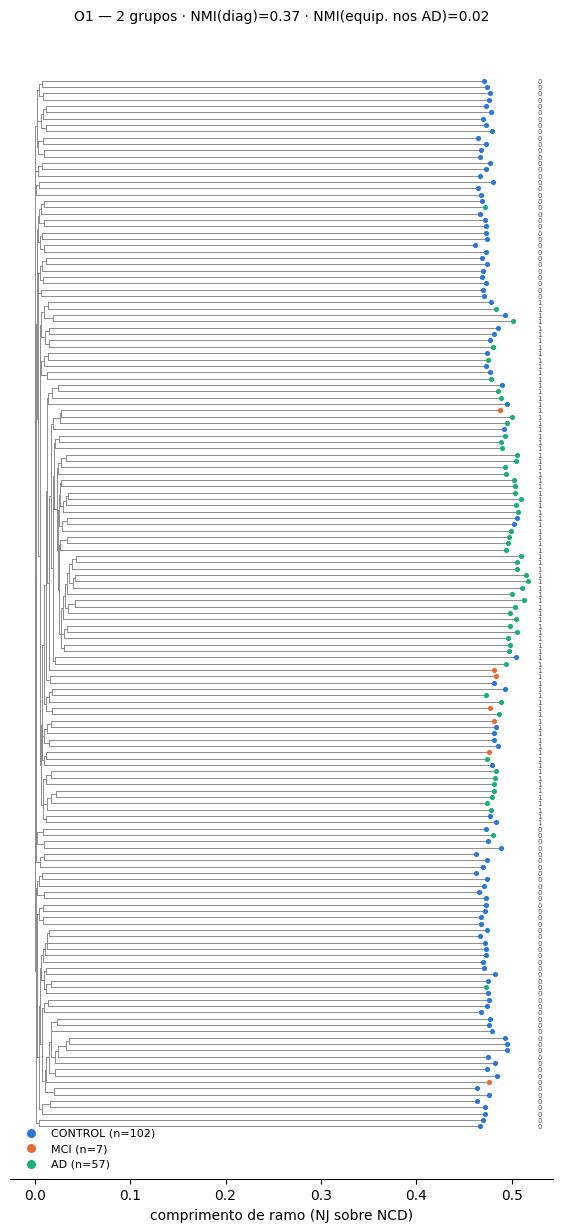

In [10]:
DIR_FIG = SAIDA / 'filogramas'
DIR_FIG.mkdir(exist_ok=True)

def layout(arvore):
    filhos, rot = {}, {n['id']: n.get('label') for n in arvore['nodes']}
    for e in arvore['edges']:
        filhos.setdefault(e['source'], []).append((e['target'], max(e['length'], 0.0)))
    alvos = {e['target'] for e in arvore['edges']}
    raiz = next(s for s in filhos if s not in alvos)
    x, y, prox = {raiz: 0.0}, {}, [0]
    def visita(n):
        if n not in filhos:
            y[n] = prox[0]; prox[0] += 1; return y[n]
        ys = []
        for f, L in filhos[n]:
            x[f] = x[n] + L; ys.append(visita(f))
        y[n] = (min(ys) + max(ys)) / 2
        return y[n]
    visita(raiz)
    return filhos, rot, x, y

def desenhar_filograma(canal, ax=None):
    filhos, rot, x, y = layout(arvores[canal])
    folhas = [n for n in x if n not in filhos]
    ax = ax or plt.subplots(figsize=(7, max(6, len(folhas) * 0.09)))[1]
    for p, fs in filhos.items():
        ys = [y[f] for f, _ in fs]
        ax.plot([x[p], x[p]], [min(ys), max(ys)], color='0.55', lw=0.7)
        for f, _ in fs:
            ax.plot([x[p], x[f]], [y[f], y[f]], color='0.55', lw=0.7)
    xmax = max(x.values())
    for n in folhas:
        pid = pid_de(rot[n]); g = meta.loc[pid, 'grupo']
        ax.scatter(x[n], y[n], s=14, color=CORES[g], zorder=3, linewidths=0)
        ax.text(xmax * 1.02, y[n], f'{discreta.loc[pid, canal]}', va='center', fontsize=5, color='0.3')
    for g in ORDEM_GRUPOS:
        ax.scatter([], [], color=CORES[g], s=30, label=f'{g} (n={(meta.grupo == g).sum()})')
    ax.legend(loc='lower left', frameon=False, fontsize=8)
    m = metricas.loc[canal]
    ax.set_title(f'{canal} — {int(m.n_clusters)} grupos · NMI(diag)={m.NMI_grupo:.2f} · NMI(equip. nos AD)={m.NMI_equip_AD:.2f}', fontsize=10)
    ax.set_yticks([]); ax.set_xlabel('comprimento de ramo (NJ sobre NCD)')
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    return ax

for canal in CANAIS:
    ax = desenhar_filograma(canal)
    ax.figure.savefig(DIR_FIG / f'filograma_{canal}.png', dpi=150, bbox_inches='tight')
    plt.close(ax.figure)

melhor = metricas.NMI_grupo.idxmax()
desenhar_filograma(melhor); plt.show()

## 6. Tabelas de probabilidade

A partir da discretização, para cada canal *c* e cluster *k*:

- **Contingência** `n(k, grupo)`, **P(grupo | k)** (o que o cluster "diz" sobre o paciente) e **P(k | grupo)** (como cada grupo se distribui no canal).
- **Tabela de probabilidade por paciente** (entrada da etapa 2): para cada paciente e canal, `P(g | cluster do paciente)` para g ∈ {CONTROL, MCI, AD}.
  Calculada em *leave-one-out* (o próprio paciente é retirado da contagem), para que a tabela não "conte" o rótulo do paciente que descreve.
- **Tabela conjunta** (formato dos slides, ex.: P(P, D1)): probabilidade das combinações de clusters num grupo de canais — usada depois que a etapa 2 indicar quais canais andam juntos.

In [11]:
# 6.1 Contingência e probabilidades condicionais (formato longo)
linhas = []
for canal in CANAIS:
    ok = discreta[canal] >= 0
    ct = pd.crosstab(discreta[canal][ok], y3[ok]).reindex(columns=ORDEM_GRUPOS, fill_value=0)
    for k, cont in ct.iterrows():
        for g in ORDEM_GRUPOS:
            linhas.append(dict(canal=canal, cluster=k, grupo=g, n=cont[g], n_cluster=cont.sum(),
                               P_grupo_dado_cluster=cont[g] / cont.sum(),
                               P_cluster_dado_grupo=cont[g] / ct[g].sum()))
prob_canal = pd.DataFrame(linhas)
prob_canal.to_csv(SAIDA / 'tabela_probabilidade_canal_cluster.csv', index=False)

# visão larga de um canal
(prob_canal[prob_canal.canal == melhor]
 .pivot(index='cluster', columns='grupo', values='P_grupo_dado_cluster')[ORDEM_GRUPOS]
 .assign(n=prob_canal[prob_canal.canal == melhor].groupby('cluster').n.sum()).round(2))

grupo,CONTROL,MCI,AD,n
cluster,,,,
0,0.95,0.01,0.04,83
1,0.28,0.07,0.65,83


In [12]:
# 6.2 Tabela de probabilidade por paciente (pacientes x [canal_grupo]) - leave-one-out
def prob_paciente(discreta, y, loo=True):
    cols = {}
    for canal in discreta:
        c = discreta[canal]; ok = (c >= 0).to_numpy()
        ct = pd.crosstab(c[ok], y[ok]).reindex(columns=ORDEM_GRUPOS, fill_value=0)
        n_k = ct.reindex(c).to_numpy(float).copy()                   # contagens do cluster de cada paciente
        if loo:
            n_k[ok] -= (y.to_numpy()[ok, None] == np.array(ORDEM_GRUPOS)[None, :])
        tot = n_k.sum(1, keepdims=True)
        p = np.divide(n_k, tot, out=np.full_like(n_k, np.nan), where=tot > 0)  # NaN: paciente sozinho no cluster
        for j, g in enumerate(ORDEM_GRUPOS):
            cols[f'{canal}_{g}'] = p[:, j]
    return pd.DataFrame(cols, index=discreta.index)

prob_pac = prob_paciente(discreta, y3)
prob_pac.round(4).to_csv(SAIDA / 'tabela_probabilidade_pacientes.csv')
print('Pacientes com alguma célula NaN (canal ausente ou sozinho no cluster):', int(prob_pac.isna().any(axis=1).sum()))
prob_pac.filter(like=f'{melhor}_').join(y3).head(8).round(2)

Pacientes com alguma célula NaN (canal ausente ou sozinho no cluster): 2


,O1_CONTROL,O1_MCI,O1_AD,grupo
paciente,,,,
AD35,0.96,0.01,0.02,AD
AD36,0.28,0.07,0.65,AD
AD37,0.28,0.07,0.65,AD
AD38,0.96,0.01,0.02,AD
AD39,0.28,0.07,0.65,AD
AD40,0.28,0.07,0.65,AD
AD41,0.28,0.07,0.65,AD
AD42,0.28,0.07,0.65,AD


In [13]:
# 6.3 Tabela conjunta para um grupo de canais (formato dos slides)
def tabela_conjunta(discreta, canais, y=None, min_prob=0.0):
    sub = discreta.loc[(discreta[canais] >= 0).all(axis=1), canais]      # só pacientes com todos os canais
    combo = sub.astype(str).agg('-'.join, axis=1).rename('combinacao')
    tab = combo.value_counts().rename('n').to_frame()
    tab['P'] = tab.n / len(combo)
    if y is not None:
        tab = tab.join(pd.crosstab(combo, y).reindex(columns=ORDEM_GRUPOS, fill_value=0)
                       .div(tab.n, axis=0).add_prefix('P_'))
    return tab[tab.P >= min_prob]

# exemplo: canais temporais/parietais posteriores citados no paper (T5, T6, P3, P4)
tabela_conjunta(discreta, ['T5', 'T6', 'P3', 'P4'], y3).head(10).round(3)

,n,P,P_CONTROL,P_MCI,P_AD
combinacao,,,,,
0-1-0-0,66,0.398,0.212,0.045,0.742
1-0-1-1,52,0.313,0.981,0.019,0.000
1-0-0-0,14,0.084,0.857,0.000,0.143
0-0-0-0,10,0.060,0.600,0.200,0.200
1-0-0-1,8,0.048,0.750,0.125,0.125
1-1-0-0,5,0.030,0.800,0.000,0.200
1-0-1-0,5,0.030,1.000,0.000,0.000
0-0-0-1,2,0.012,0.500,0.000,0.500
0-0-1-1,2,0.012,1.000,0.000,0.000


## 7. Resumo visual: composição dos clusters por canal

Um painel por canal; cada barra é um cluster (altura = nº de pacientes, segmentos = diagnóstico), ordenados da maior para a menor fração de controles.

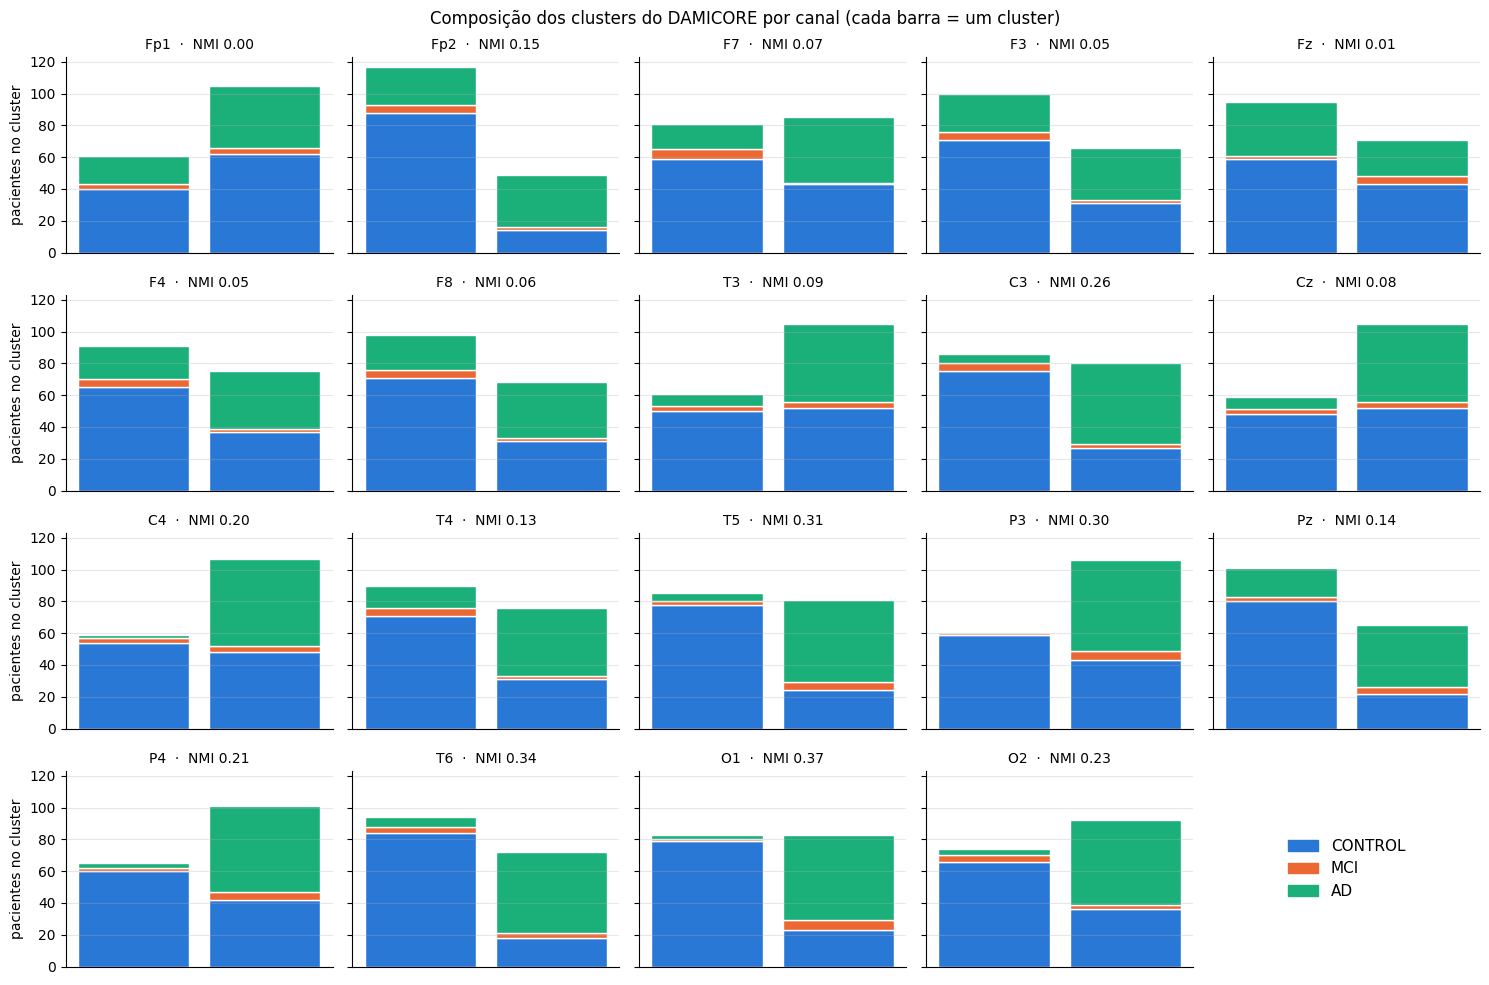

In [14]:
fig, eixos = plt.subplots(4, 5, figsize=(15, 10), sharey=True)
for ax, canal in zip(eixos.flat, CANAIS):
    ok = discreta[canal] >= 0
    ct = pd.crosstab(discreta[canal][ok], y3[ok]).reindex(columns=ORDEM_GRUPOS, fill_value=0)
    ct = ct.loc[(ct.CONTROL / ct.sum(axis=1)).sort_values(ascending=False).index]   # mais "controle" à esquerda
    base = np.zeros(len(ct))
    for g in ORDEM_GRUPOS:
        ax.bar(range(len(ct)), ct[g], bottom=base, color=CORES[g], width=0.85, edgecolor='white', linewidth=1)
        base += ct[g].to_numpy()
    m = metricas.loc[canal]
    ax.set_title(f'{canal}  ·  NMI {m.NMI_grupo:.2f}', fontsize=10)
    ax.set_xticks([]); ax.grid(axis='y', alpha=.3)
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)
eixos.flat[-1].axis('off')
eixos.flat[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CORES[g]) for g in ORDEM_GRUPOS],
                      labels=ORDEM_GRUPOS, frameon=False, loc='center', fontsize=11)
for ax in eixos[:, 0]:
    ax.set_ylabel('pacientes no cluster')
fig.suptitle('Composição dos clusters do DAMICORE por canal (cada barra = um cluster)', fontsize=12)
plt.tight_layout(); plt.savefig(SAIDA / 'composicao_clusters.png', dpi=150); plt.show()

## 8. Etapa 2 — tabela de probabilidade marginal (transposta) e DAMICORE entre pacientes

**Construção da tabela** a partir da tabela discretizada da etapa 1:

1. **Tabela marginal por canal:** a frequência de cada valor (cluster) em cada canal, P(canal = v), calculada sobre os pacientes. Não usa o diagnóstico.
2. **Tabela de probabilidade por paciente, já transposta:** linhas = canais, colunas = pacientes. Cada célula é a probabilidade
   do valor que aquele paciente tem naquele canal. Exemplo: no T6, P(0) = 0,434 e P(1) = 0,566; um paciente no cluster 1 do T6 recebe `0.5660`.
3. **DAMICORE com `split='columns'`:** cada coluna (paciente) é um objeto. O CSV **não tem coluna com o nome dos canais**,
   porque o DAMICORE transformaria essa coluna em mais um objeto; a ordem das linhas é a ordem de `CANAIS_ETAPA2`.

Propriedades e cuidados:

- **Não depende do alinhamento dos rótulos:** trocar 0 e 1 num canal não muda a probabilidade do valor de cada paciente.
- **Canal com P ≈ 50% não informa:** os pacientes dos dois grupos recebem o mesmo número (com k=2, o O1 tem exatamente 50% / 50%). O notebook avisa quando isso acontece.
- **Perfis idênticos:** pacientes com a mesma coluna têm NCD = 0. Com poucos canais isso é comum e pode quebrar o FastGreedy (`Branch length is zero`).
  Com `AGRUPAR_PERFIS = 'auto'`, o DAMICORE roda primeiro com um objeto por paciente; só se a árvore quebrar, as colunas idênticas são juntadas num
  único **perfil**, e o grupo do perfil volta para cada paciente depois. Juntar não perde informação, mas **muda o resultado**: 10 pacientes idênticos passam a pesar
  como um objeto só (com os 19 canais e k=2, a NMI com o diagnóstico foi de 0,33 por paciente e de 0,20 por perfil). `True` força o agrupamento; `False` o proíbe.
- Valores com `CASAS` casas decimais fixas: o NCD compara texto, então mudar a formatação muda as distâncias.
- O diagnóstico só entra no fim, para avaliar.

In [15]:
# ---- parâmetros da etapa 2 ----
ETAPA1 = 'k2'              # discretização usada: 'auto', 'k2', 'k3'... (arquivo tabela_discretizada_<ETAPA1>.csv)
CANAIS_ETAPA2 = CANAIS     # todos; ou um subconjunto, ex.: ['T5', 'T6', 'P3', 'P4', 'O1', 'O2']
K_ETAPA2 = 2               # None = FastGreedy decide; 2, 3, ...
CASAS = 4                  # casas decimais das probabilidades na tabela
AGRUPAR_PERFIS = 'auto'    # 'auto' = junta pacientes idênticos só se a árvore quebrar; True = sempre; False = nunca

In [16]:
DIR_E2 = SAIDA / 'etapa2'

def carregar_discreta(etapa1):
    caminho = SAIDA / f'tabela_discretizada_{etapa1}.csv'
    if not caminho.exists():
        raise FileNotFoundError(f'{caminho.name} não existe: rode a seção 4 com o NUM_CLUSTERS correspondente a "{etapa1}"')
    return pd.read_csv(caminho, index_col=0).replace(-1, np.nan)        # -1 = canal ausente

def tabela_marginal(disc, canais):
    # Formato longo: canal, valor, n, P(canal = valor). Ignora canais ausentes.
    linhas = []
    for c in canais:
        freq = disc[c].dropna().astype(int).value_counts().sort_index()
        for v, n in freq.items():
            linhas.append(dict(canal=c, valor=int(v), n=int(n), P=n / freq.sum()))
    return pd.DataFrame(linhas)

def tabela_probabilidade_transposta(disc, canais, casas=CASAS):
    # Canais x pacientes; célula = P(canal = valor do paciente), em texto com casas fixas ('NA' se ausente).
    marg = tabela_marginal(disc, canais).set_index(['canal', 'valor']).P
    tab = pd.DataFrame({c: [marg[(c, int(v))] if pd.notna(v) else np.nan for v in disc[c]] for c in canais},
                       index=disc.index).T
    return tab.map(lambda p: 'NA' if pd.isna(p) else f'{p:.{casas}f}')

def agrupar_perfis(tab):
    # Junta pacientes com colunas idênticas. Devolve (tabela de perfis únicos, série paciente -> perfil).
    chave = tab.T.apply(tuple, axis=1)
    ids = {}
    for k in chave:                                    # ordem de primeira aparição = ordem da tabela discretizada
        ids.setdefault(k, f'perfil_{len(ids) + 1:03d}')
    perfil = chave.map(ids).rename('perfil')
    unicos = tab.loc[:, ~chave.duplicated().to_numpy()]
    unicos.columns = perfil[unicos.columns].to_numpy()
    return unicos, perfil

def canais_nao_informativos(disc, canais, tol=0.01):
    # Canais em que todos os valores têm a mesma frequência (ex.: 50% / 50%): todos os pacientes recebem o mesmo número.
    m = tabela_marginal(disc, canais)
    return [c for c, g in m.groupby('canal', sort=False) if g.P.max() - g.P.min() < tol]

In [17]:
def rodar_damicore_tabela(arquivo, k, saida_dir):
    args = dict(split='columns', num_clusters=k, output_dir=saida_dir, progress=False,
                execution=ExecutionConfig(workers='auto'))
    try:
        r = run(arquivo, **args)                  # reaproveita a execução se a entrada não mudou
    except OutputDirectoryConflictError:          # entrada mudou: refaz
        shutil.rmtree(saida_dir); r = run(arquivo, **args)
    out = (pd.Series(r.membership['cluster'].values, index=r.membership['label']),
           json.loads(r.artifacts.tree_json.read_text()), r.report.modularity)
    r.close()
    return out

def etapa2(etapa1=ETAPA1, canais=CANAIS_ETAPA2, k=K_ETAPA2, casas=CASAS, agrupar=AGRUPAR_PERFIS, mostrar=True):
    # Monta a tabela de probabilidade transposta e roda o DAMICORE entre pacientes. Uma chamada = um experimento.
    canais = list(canais)
    disc = carregar_discreta(etapa1)
    tag_canais = 'todos' if canais == list(CANAIS) else '-'.join(canais)
    destino = DIR_E2 / f'{etapa1}__{tag_canais}__k{k if k is not None else "auto"}__c{casas}'
    destino.mkdir(parents=True, exist_ok=True)

    # 1) tabelas
    marginal = tabela_marginal(disc, canais)
    tab = tabela_probabilidade_transposta(disc, canais, casas)
    unicos, perfil = agrupar_perfis(tab)
    marginal.to_csv(destino / 'tabela_marginal_por_canal.csv', index=False)
    tab.to_csv(destino / 'tabela_probabilidade_transposta.csv', index=False)      # canais x pacientes, sem coluna de rótulo
    unicos.to_csv(destino / 'tabela_perfis_unicos.csv', index=False)             # mesma tabela, colunas idênticas juntadas
    perfil.to_csv(destino / 'paciente_perfil.csv')

    avisos = canais_nao_informativos(disc, canais)
    if avisos:
        print(f'Aviso: canais sem informação nesta tabela (valores equiprováveis): {avisos}')
    print(f'{tab.shape[1]} pacientes -> {unicos.shape[1]} perfis distintos; {len(canais)} canais; discretização "{etapa1}"')
    if unicos.shape[1] < 3:
        raise ValueError('Menos de 3 perfis distintos: não há o que agrupar. Use mais canais.')
    if k is not None and k > unicos.shape[1]:
        raise ValueError(f'k={k} maior que o número de perfis distintos ({unicos.shape[1]}).')

    # 2) DAMICORE: objeto = paciente; se houver perfis idênticos que quebrem a árvore, objeto = perfil
    if agrupar is True:
        usar_perfis = True
    else:
        try:
            grupo_obj, arvore, modularidade = rodar_damicore_tabela(
                destino / 'tabela_probabilidade_transposta.csv', k, destino / 'damicore_pacientes')
            usar_perfis = False
        except TreeFormatError:
            if agrupar is False:
                raise
            print('Pacientes com perfis idênticos quebraram a árvore (ramo de comprimento zero): '
                  'repetindo com as colunas idênticas juntadas em perfis.')
            usar_perfis = True
    if usar_perfis:
        grupo_obj, arvore, modularidade = rodar_damicore_tabela(
            destino / 'tabela_perfis_unicos.csv', k, destino / 'damicore_perfis')
    print('Objetos do DAMICORE:', 'perfis únicos' if usar_perfis else 'pacientes')

    # 3) resultado por paciente + avaliação (o diagnóstico só entra aqui)
    res = meta.drop(columns='arquivos').loc[tab.columns, ['grupo', 'equipamento', 'escore_total']].copy()
    res.insert(0, 'perfil', perfil)
    res.insert(1, 'objeto', perfil if usar_perfis else res.index.to_series())   # rótulo do objeto no DAMICORE
    res.insert(2, 'cluster', res.objeto.map(grupo_obj))
    res.to_csv(destino / 'resultado_pacientes.csv')
    tabela = pd.crosstab(res.cluster, res.grupo).reindex(columns=ORDEM_GRUPOS, fill_value=0)
    tabela.to_csv(destino / 'cluster_x_diagnostico.csv')
    ad = res.grupo == 'AD'
    aval = pd.Series(dict(
        n_objetos=res.objeto.nunique(), n_clusters=res.cluster.nunique(), modularidade=modularidade,
        NMI_grupo=normalized_mutual_info_score(res.grupo, res.cluster),
        ARI_grupo=adjusted_rand_score(res.grupo, res.cluster),
        NMI_binario=normalized_mutual_info_score(res.grupo != 'CONTROL', res.cluster),
        pureza=pureza(res.cluster, res.grupo),
        NMI_equip_AD=normalized_mutual_info_score(res.equipamento[ad], res.cluster[ad])))
    aval.to_csv(destino / 'avaliacao.csv', header=['valor'])

    saida = dict(destino=destino, tabela_transposta=tab, perfis=unicos, resultado=res, usar_perfis=usar_perfis,
                 cluster_x_diagnostico=tabela, avaliacao=aval, arvore=arvore)
    if mostrar:
        print(f'Resultados em: {destino}')
        display(tabela.assign(total=tabela.sum(axis=1)))
        display(aval.round(3).to_frame('valor').T)
        desenhar_etapa2(saida)
    return saida

In [18]:
def desenhar_etapa2(saida):
    # Filograma (folha = paciente, ou perfil quando agrupado; cor = diagnóstico majoritário; tamanho = nº de pacientes) + composição.
    res, arvore = saida['resultado'], saida['arvore']
    filhos, rot, x, y = layout(arvore)
    folhas = [n for n in x if n not in filhos]
    comp = pd.crosstab(res.objeto, res.grupo).reindex(columns=ORDEM_GRUPOS, fill_value=0)
    cl_perfil = res.groupby('objeto').cluster.first()
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, max(6, len(folhas) * 0.1)), gridspec_kw=dict(width_ratios=[3, 1.2]))
    for p, fs in filhos.items():
        ys = [y[f] for f, _ in fs]
        ax.plot([x[p], x[p]], [min(ys), max(ys)], color='0.55', lw=0.7)
        for f, _ in fs:
            ax.plot([x[p], x[f]], [y[f], y[f]], color='0.55', lw=0.7)
    xmax = max(x.values())
    for n in folhas:
        c = comp.loc[rot[n]]
        ax.scatter(x[n], y[n], s=12 + 6 * c.sum(), color=CORES[c.idxmax()], zorder=3, linewidths=0)
        ax.text(xmax * 1.02, y[n], f'k{cl_perfil[rot[n]]}  {c.CONTROL}/{c.MCI}/{c.AD}', va='center', fontsize=5, color='0.3')
    for g in ORDEM_GRUPOS:
        ax.scatter([], [], color=CORES[g], s=30, label=g)
    ax.legend(loc='lower left', frameon=False, fontsize=8, title='diagnóstico (majoritário, se perfil)', title_fontsize=8)
    av = saida['avaliacao']
    ax.set_title(f'Etapa 2 — {saida["destino"].name}\n{int(av.n_clusters)} grupos · NMI(diag)={av.NMI_grupo:.2f} · '
                 f'NMI(equip. nos AD)={av.NMI_equip_AD:.2f}   (texto à direita: cluster  CONTROL/MCI/AD)', fontsize=9)
    ax.set_yticks([]); ax.set_xlabel('comprimento de ramo (NJ sobre NCD)')
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)

    tabela = saida['cluster_x_diagnostico']
    base = np.zeros(len(tabela))
    for g in ORDEM_GRUPOS:
        ax2.bar([str(i) for i in tabela.index], tabela[g], bottom=base, color=CORES[g], edgecolor='white', linewidth=1, label=g)
        base += tabela[g].to_numpy()
    ax2.set_xlabel('cluster'); ax2.set_ylabel('pacientes'); ax2.set_title('Composição dos clusters', fontsize=9)
    ax2.legend(frameon=False, fontsize=8); ax2.grid(axis='y', alpha=.3)
    for s in ['top', 'right']:
        ax2.spines[s].set_visible(False)
    plt.tight_layout(); plt.savefig(saida['destino'] / 'etapa2.png', dpi=150, bbox_inches='tight'); plt.show()

### 8.1 Execução

Ajuste `ETAPA1`, `CANAIS_ETAPA2`, `K_ETAPA2` e `CASAS` na célula de parâmetros, ou passe os valores direto na chamada.
Cada combinação vai para a sua pasta em `resultados/etapa2/<etapa1>__<canais>__k<k>__c<casas>/`, com:
`tabela_marginal_por_canal.csv`, `tabela_probabilidade_transposta.csv` (canais × pacientes; entrada do DAMICORE),
`tabela_perfis_unicos.csv` e `paciente_perfil.csv` (usados só se houver agrupamento), `resultado_pacientes.csv`, `cluster_x_diagnostico.csv`,
`avaliacao.csv`, `etapa2.png` e `damicore_pacientes/` ou `damicore_perfis/` com os artefatos do DAMICORE.

Aviso: canais sem informação nesta tabela (valores equiprováveis): ['O1']
166 pacientes -> 111 perfis distintos; 19 canais; discretização "k2"
Objetos do DAMICORE: pacientes


Resultados em: C:\DAMICORE\resultados\etapa2\k2__todos__k2__c4


grupo,CONTROL,MCI,AD,total
cluster,,,,
0,80,5,8,93
1,22,2,49,73


,n_objetos,n_clusters,modularidade,NMI_grupo,ARI_grupo,NMI_binario,pureza,NMI_equip_AD
valor,166.0,2.0,0.49,0.271,0.348,0.253,0.777,0.253


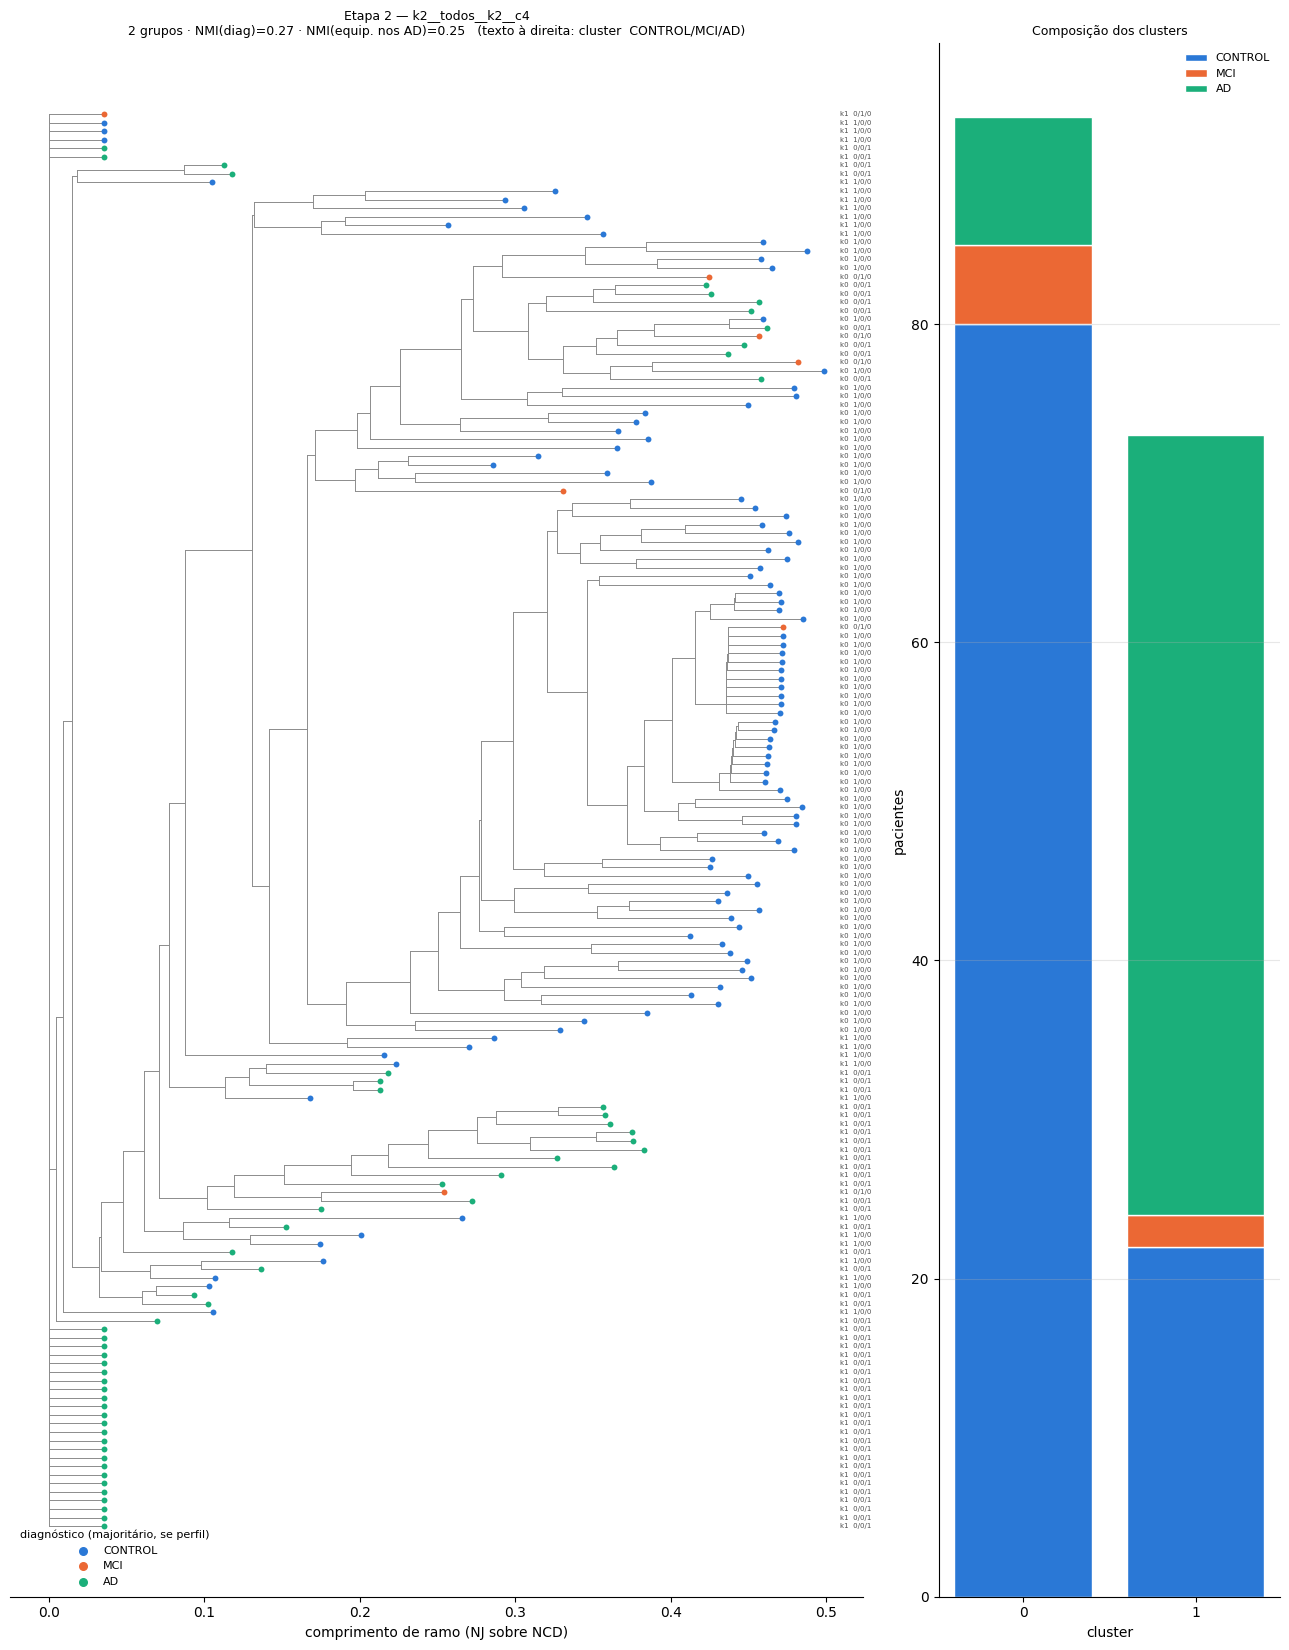

paciente,AD35,AD36,AD37,AD38,AD39,AD40
Fp1,0.3675,0.6325,0.3675,0.3675,0.6325,0.6325
Fp2,0.7048,0.2952,0.7048,0.7048,0.2952,0.7048
F7,0.4880,0.5120,0.5120,0.4880,0.5120,0.5120
F3,0.6024,0.6024,0.6024,0.6024,0.6024,0.3976
Fz,0.4277,0.5723,0.4277,0.4277,0.4277,0.5723


In [19]:
e2 = etapa2()                                   # usa os parâmetros acima
e2['tabela_transposta'].iloc[:5, :6]             # amostra da tabela: canais x pacientes

In [20]:
# Outros experimentos, uma chamada cada (descomente):
# e2_k3   = etapa2(k=3)
# e2_post = etapa2(canais=['T5', 'T6', 'P3', 'P4', 'O1', 'O2'], k=2)   # poucos canais: provavelmente vai agrupar perfis
# e2_perf = etapa2(agrupar=True)                                         # força o agrupamento em perfis, para comparar
# e2_auto = etapa2(k=None)

## 9. Comparação: DAMICORE nos dados crus (sem harmonização)

Para entender o que a harmonização muda, o DAMICORE roda aqui por canal **direto nos valores originais dos arquivos**:

- **sem** reamostragem (256 Hz e 128 Hz ficam como estão), **sem** filtro, **sem** z-score e **sem** quantização;
- cada objeto é a sequência de valores `float32` do canal, exatamente como estão no `.mat` (unidades originais);
- única manipulação: ler as 19 linhas/colunas de EEG, concatenar os segmentos de cada paciente e recortar uma janela central.

**Tamanho da janela:** `N_AMOSTRAS_BRUTO = 3840` amostras × 4 bytes = 15 KB por objeto. O zlib só encontra repetições até 32 KB para trás;
se o par de objetos concatenados passar disso, o NCD fica ≈ 1 para todos os pares. Por isso a janela é fixa em **amostras**, não em segundos:
são 30 s nos registros a 128 Hz e 15 s nos de 256 Hz.

**O que esperar:** os 100 controles `fir` estão gravados como números inteiros (µV), e o resto como decimais. Como o NCD mede compressibilidade,
o formato do arquivo pesa muito. Por isso há uma métrica a mais, `NMI_formato` (`fir` × `export`), e a avaliação **só entre os arquivos `export`**
(57 AD, 7 MCI, 2 controles), onde o formato é o mesmo para todos.

O DAMICORE roda uma vez por canal (k automático); os cortes em outros k reaproveitam a mesma árvore (`damicore_clusterizer.cluster_tree`), sem recalcular o NCD.
A primeira execução leva ~70 s por canal (~25 min no total).

In [21]:
# ---- parâmetros da comparação com dados crus ----
N_AMOSTRAS_BRUTO = 3840        # float32 -> 15 KB por objeto (par < 32 KB, janela do zlib)
K_BRUTO = [2, 3]               # cortes extras da mesma árvore (k automático sempre roda)

In [22]:
from damicore_clusterizer import cluster_tree
from damicore_clusterizer.config import ClusterConfig
import hashlib, zlib

DIR_BRUTO = SAIDA / 'bruto' / f'n{N_AMOSTRAS_BRUTO}'
DIR_OBJ_BRUTO = DIR_BRUTO / 'objetos'
meta['formato_arquivo'] = np.where(meta.formato == 'fir', 'fir (inteiros)', 'export (decimais)')

# 1) objetos crus: valores float32 originais, janela central, sem nenhum processamento
if DIR_OBJ_BRUTO.exists():
    shutil.rmtree(DIR_OBJ_BRUTO)
planos_bruto, taxa = [], []
for pid, linha in meta.iterrows():
    x = np.concatenate(ler_segmentos(linha)).astype(np.float32)        # amostras x 19, na frequência e unidade originais
    if len(x) < N_AMOSTRAS_BRUTO:
        raise ValueError(f'{pid}: só {len(x)} amostras')
    ini = (len(x) - N_AMOSTRAS_BRUTO) // 2
    x = x[ini:ini + N_AMOSTRAS_BRUTO]
    for i, canal in enumerate(CANAIS):
        if x[:, i].std() == 0:
            planos_bruto.append((pid, canal)); continue                 # eletrodo morto: objetos idênticos quebrariam a árvore
        b = np.ascontiguousarray(x[:, i]).tobytes()
        (DIR_OBJ_BRUTO / canal).mkdir(parents=True, exist_ok=True)
        (DIR_OBJ_BRUTO / canal / f"{linha.grupo}__{pid}.bin").write_bytes(b)
        taxa.append(dict(paciente=pid, canal=canal, formato=meta.loc[pid, 'formato_arquivo'], grupo=linha.grupo,
                         taxa_compressao=len(zlib.compress(b, 6)) / len(b)))
taxa = pd.DataFrame(taxa)
print('Canais planos (excluídos daquele canal):', planos_bruto or 'nenhum')
print('\nTamanho comprimido / original (zlib), média por formato e diagnóstico:')
taxa.pivot_table(index='formato', columns='grupo', values='taxa_compressao', aggfunc='mean').round(3)

Canais planos (excluídos daquele canal): [('26887fir', 'Cz'), ('7147fir', 'Cz')]

Tamanho comprimido / original (zlib), média por formato e diagnóstico:


grupo,AD,CONTROL,MCI
formato,,,
export (decimais),0.925,0.929,0.928
fir (inteiros),NaN,0.315,NaN


In [23]:
# 2) DAMICORE por canal (k automático) + cortes da mesma árvore em K_BRUTO
def cortar_arvore(tree_json, destino, k):
    # Corta uma árvore já calculada em k grupos; refaz o corte se a árvore mudou.
    sha = hashlib.sha256(Path(tree_json).read_bytes()).hexdigest()
    marca = destino / 'arvore.sha256'
    if destino.exists() and (not marca.exists() or marca.read_text() != sha):
        shutil.rmtree(destino)
    if not (destino / 'membership.csv').exists():
        cluster_tree(tree_json, destino, config=ClusterConfig(num_clusters=k))
        marca.write_text(sha)
    return pd.read_csv(destino / 'membership.csv')

membros_bruto, arvores_bruto = {}, {}
for canal in CANAIS:
    destino = DIR_BRUTO / 'damicore' / canal
    args = dict(source_kind='files', output_dir=destino, progress=False, execution=ExecutionConfig(workers='auto'))
    try:
        r = run(DIR_OBJ_BRUTO / canal, **args)
    except OutputDirectoryConflictError:
        shutil.rmtree(destino); r = run(DIR_OBJ_BRUTO / canal, **args)
    arvores_bruto[canal] = json.loads(r.artifacts.tree_json.read_text())
    cortes = {'auto': r.membership}
    for k in K_BRUTO:
        cortes[f'k{k}'] = cortar_arvore(r.artifacts.tree_json, DIR_BRUTO / 'cortes' / canal / f'k{k}', k)
    membros_bruto[canal] = {nome: pd.Series(mb['cluster'].values, index=mb['label'].map(pid_de)) for nome, mb in cortes.items()}
    print(f'{canal:>3}: k automático = {membros_bruto[canal]["auto"].nunique()} grupos (NCD {r.report.ncd_min:.2f}–{r.report.ncd_max:.2f})')
    r.close()

Fp1: k automático = 17 grupos (NCD 0.00–1.08)


Fp2: k automático = 17 grupos (NCD 0.00–1.08)


 F7: k automático = 19 grupos (NCD 0.00–1.08)


 F3: k automático = 18 grupos (NCD 0.00–1.08)


 Fz: k automático = 19 grupos (NCD 0.00–1.08)


...

 Pz: k automático = 19 grupos (NCD 0.00–1.08)


 P4: k automático = 18 grupos (NCD 0.00–1.08)


 T6: k automático = 18 grupos (NCD 0.00–1.08)


 O1: k automático = 16 grupos (NCD 0.00–1.08)


 O2: k automático = 20 grupos (NCD 0.00–1.08)


In [24]:
# 3) métricas: todos os pacientes e só os arquivos 'export' (formato homogêneo)
def metricas_bruto(c):
    m = meta.loc[c.index]
    exp_ = m.formato == 'export'
    ad = m.grupo == 'AD'
    return dict(n_clusters=c.nunique(),
                NMI_grupo=normalized_mutual_info_score(m.grupo, c),
                NMI_binario=normalized_mutual_info_score(m.grupo != 'CONTROL', c),
                NMI_formato=normalized_mutual_info_score(m.formato, c),
                NMI_grupo_export=normalized_mutual_info_score(m.grupo[exp_], c[exp_]),
                NMI_equip_AD=normalized_mutual_info_score(m.equipamento[ad], c[ad]))

linhas = []
for canal in CANAIS:
    for corte, c in membros_bruto[canal].items():
        linhas.append(dict(canal=canal, corte=corte, **metricas_bruto(c)))
metricas_bruto_df = pd.DataFrame(linhas)
metricas_bruto_df.to_csv(DIR_BRUTO / 'metricas_por_canal.csv', index=False)

resumo = metricas_bruto_df.groupby('corte')[['n_clusters', 'NMI_grupo', 'NMI_formato', 'NMI_grupo_export', 'NMI_equip_AD']].mean()
print('Média dos 19 canais por corte:')
display(resumo.round(3))
corte_ver = f'k{K_BRUTO[0]}' if K_BRUTO else 'auto'
print(f'\nPor canal, corte {corte_ver}:')
metricas_bruto_df[metricas_bruto_df.corte == corte_ver].set_index('canal').drop(columns='corte').sort_values('NMI_grupo', ascending=False).round(3)

Média dos 19 canais por corte:


,n_clusters,NMI_grupo,NMI_formato,NMI_grupo_export,NMI_equip_AD
corte,,,,,
auto,18.0,0.406,0.378,0.270,0.155
k2,2.0,0.629,0.729,0.050,0.027
k3,3.0,0.569,0.628,0.125,0.073



Por canal, corte k2:


,n_clusters,NMI_grupo,NMI_binario,NMI_formato,NMI_grupo_export,NMI_equip_AD
canal,,,,,,
Fp2,2,0.833,0.915,1.000,0.000,0.000
F7,2,0.833,0.915,1.000,0.000,0.000
Fz,2,0.833,0.915,1.000,0.000,0.000
P4,2,0.833,0.915,1.000,0.000,0.000
T3,2,0.833,0.915,1.000,0.000,0.000
C3,2,0.833,0.915,1.000,0.000,0.000
O1,2,0.833,0.915,1.000,0.000,0.000
Pz,2,0.756,0.830,0.885,0.000,0.000
T4,2,0.627,0.689,0.725,0.000,0.000


In [25]:
# 4) composição dos grupos no melhor canal: diagnóstico x formato do arquivo
melhor_bruto = (metricas_bruto_df[metricas_bruto_df.corte == corte_ver].set_index('canal').NMI_grupo.idxmax())
c = membros_bruto[melhor_bruto][corte_ver]
print(f'Canal {melhor_bruto}, corte {corte_ver}: cluster x (diagnóstico | formato | aparelho)')
pd.crosstab(meta.loc[c.index, 'grupo'] + ' | ' + meta.loc[c.index, 'formato_arquivo'] + ' | ' + meta.loc[c.index, 'equipamento'],
            c.rename('cluster'))

Canal Fp2, corte k2: cluster x (diagnóstico | formato | aparelho)


cluster,0,1
row_0,,
AD | export (decimais) | Alien-128Hz,24,0
AD | export (decimais) | Walter-256Hz,33,0
CONTROL | export (decimais) | Alien-128Hz,2,0
CONTROL | fir (inteiros) | Alien-128Hz-fir,0,100
MCI | export (decimais) | Alien-128Hz,3,0
MCI | export (decimais) | Walter-256Hz,4,0


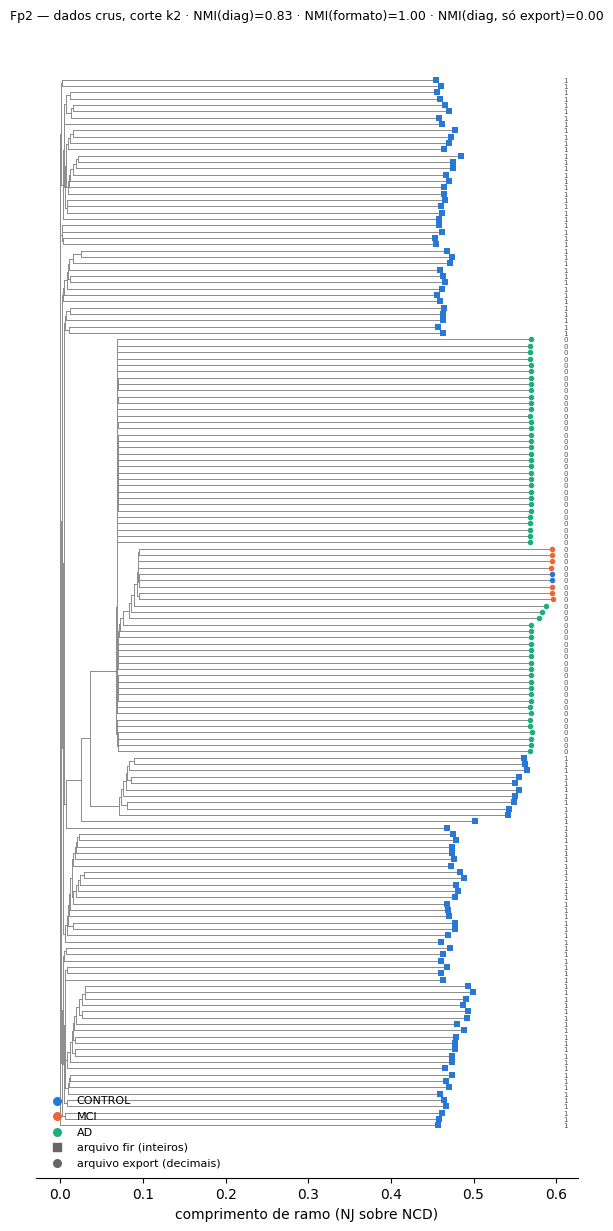

In [26]:
# 5) filograma cru do melhor canal: cor = diagnóstico, forma = formato do arquivo
def desenhar_filograma_bruto(canal, corte=corte_ver):
    filhos, rot, x, y = layout(arvores_bruto[canal])
    folhas = [n for n in x if n not in filhos]
    fig, ax = plt.subplots(figsize=(7, max(6, len(folhas) * 0.09)))
    for p, fs in filhos.items():
        ys = [y[f] for f, _ in fs]
        ax.plot([x[p], x[p]], [min(ys), max(ys)], color='0.55', lw=0.7)
        for f, _ in fs:
            ax.plot([x[p], x[f]], [y[f], y[f]], color='0.55', lw=0.7)
    xmax = max(x.values())
    cl = membros_bruto[canal][corte]
    for n in folhas:
        pid = pid_de(rot[n])
        ax.scatter(x[n], y[n], s=16, color=CORES[meta.loc[pid, 'grupo']], zorder=3, linewidths=0,
                   marker='s' if meta.loc[pid, 'formato'] == 'fir' else 'o')
        ax.text(xmax * 1.02, y[n], f'{cl[pid]}', va='center', fontsize=5, color='0.3')
    for g in ORDEM_GRUPOS:
        ax.scatter([], [], color=CORES[g], s=30, label=g)
    ax.scatter([], [], color='0.4', marker='s', s=30, label='arquivo fir (inteiros)')
    ax.scatter([], [], color='0.4', marker='o', s=30, label='arquivo export (decimais)')
    ax.legend(loc='lower left', frameon=False, fontsize=8)
    m = metricas_bruto_df.query('canal == @canal and corte == @corte').iloc[0]
    ax.set_title(f'{canal} — dados crus, corte {corte} · NMI(diag)={m.NMI_grupo:.2f} · NMI(formato)={m.NMI_formato:.2f} '
                 f'· NMI(diag, só export)={m.NMI_grupo_export:.2f}', fontsize=9)
    ax.set_yticks([]); ax.set_xlabel('comprimento de ramo (NJ sobre NCD)')
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    return ax

(DIR_BRUTO / 'filogramas').mkdir(exist_ok=True)
for canal in CANAIS:
    ax = desenhar_filograma_bruto(canal)
    ax.figure.savefig(DIR_BRUTO / 'filogramas' / f'filograma_{canal}.png', dpi=150, bbox_inches='tight')
    plt.close(ax.figure)
desenhar_filograma_bruto(melhor_bruto); plt.show()

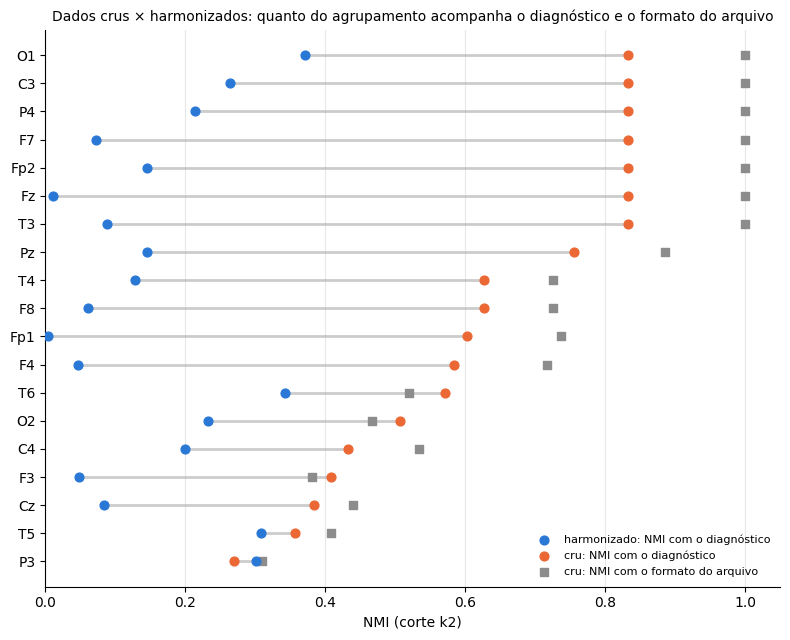

,harmonizado_NMI_grupo,harmonizado_NMI_formato,bruto_NMI_grupo,bruto_NMI_formato,bruto_NMI_grupo_export
Fp2,0.145,0.137,0.833,1.000,0.000
F7,0.072,0.030,0.833,1.000,0.000
Fz,0.010,0.001,0.833,1.000,0.000
P4,0.214,0.187,0.833,1.000,0.000
T3,0.087,0.065,0.833,1.000,0.000
C3,0.264,0.211,0.833,1.000,0.000
O1,0.371,0.394,0.833,1.000,0.000
Pz,0.144,0.142,0.756,0.885,0.000
T4,0.128,0.100,0.627,0.725,0.000
F8,0.061,0.046,0.627,0.725,0.000


In [27]:
# 6) comparação com a versão harmonizada (mesmo corte), quando existir
def membros_harmonizados(corte):
    suf = '' if corte == 'auto' else f'_{corte}'
    out = {}
    for canal in CANAIS:
        f = DIR_DMC / f'{canal}{suf}' / 'membership.csv'                  # execuções harmonizadas da seção 4
        if f.exists():
            mb = pd.read_csv(f); out[canal] = pd.Series(mb['cluster'].values, index=mb['label'].map(pid_de))
    return out

harm = membros_harmonizados(corte_ver)
if len(harm) < len(CANAIS):
    print(f'Versão harmonizada com corte {corte_ver} não encontrada para todos os canais: rode a seção 4 com NUM_CLUSTERS = {corte_ver[1:]}.')
else:
    comp = pd.DataFrame({canal: dict(
        harmonizado_NMI_grupo=metricas_bruto(harm[canal])['NMI_grupo'],
        harmonizado_NMI_formato=metricas_bruto(harm[canal])['NMI_formato'],
        bruto_NMI_grupo=metricas_bruto(membros_bruto[canal][corte_ver])['NMI_grupo'],
        bruto_NMI_formato=metricas_bruto(membros_bruto[canal][corte_ver])['NMI_formato'],
        bruto_NMI_grupo_export=metricas_bruto(membros_bruto[canal][corte_ver])['NMI_grupo_export'])
        for canal in CANAIS}).T
    comp.to_csv(DIR_BRUTO / f'comparacao_harmonizado_{corte_ver}.csv')

    ordem = comp.sort_values('bruto_NMI_grupo').index
    fig, ax = plt.subplots(figsize=(8, 6.5))
    yy = np.arange(len(ordem))
    for i, canal in enumerate(ordem):
        ax.plot([comp.loc[canal, 'harmonizado_NMI_grupo'], comp.loc[canal, 'bruto_NMI_grupo']], [i, i], color='0.8', lw=2, zorder=1)
    ax.scatter(comp.loc[ordem, 'harmonizado_NMI_grupo'], yy, color='#2a78d6', s=40, zorder=3, label='harmonizado: NMI com o diagnóstico')
    ax.scatter(comp.loc[ordem, 'bruto_NMI_grupo'], yy, color='#eb6834', s=40, zorder=3, label='cru: NMI com o diagnóstico')
    ax.scatter(comp.loc[ordem, 'bruto_NMI_formato'], yy, color='0.55', marker='s', s=30, zorder=2, label='cru: NMI com o formato do arquivo')
    ax.set_yticks(yy, ordem); ax.set_xlabel(f'NMI (corte {corte_ver})'); ax.set_xlim(0, None)
    ax.set_title('Dados crus × harmonizados: quanto do agrupamento acompanha o diagnóstico e o formato do arquivo', fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc='lower right'); ax.grid(axis='x', alpha=.3)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.savefig(DIR_BRUTO / f'comparacao_harmonizado_{corte_ver}.png', dpi=150); plt.show()
    display(comp.round(3).sort_values('bruto_NMI_grupo', ascending=False))

## 10. Arquivos gerados e próximos passos

**Etapa 1 (`resultados/`):** `tabela_discretizada.csv` e `tabela_discretizada_<auto|k2|…>.csv`, `metadados_pacientes.csv`, `metricas_por_canal.csv`,
`tabela_probabilidade_canal_cluster.csv`, `tabela_probabilidade_pacientes.csv`, `psd_harmonizacao.png`, `composicao_clusters.png`,
`filogramas/filograma_<canal>.png`, e `damicore/<TAG>/<canal>[_k<k>]/` com os artefatos de cada execução.

**Etapa 2 (`resultados/etapa2/<etapa1>__<canais>__k<k>__c<casas>/`):** ver seção 8.1.

**Dados crus (`resultados/bruto/n<amostras>/`):** objetos, `damicore/<canal>/`, `cortes/<canal>/k<k>/`, `metricas_por_canal.csv`,
`filogramas/`, e a comparação com a versão harmonizada (`comparacao_harmonizado_<corte>.csv/.png`).

Próximos passos possíveis: as tabelas conjuntas (seção 6.3) e o DAMICORE sobre os canais (colunas da tabela discretizada),
para encontrar grupos de canais como nos slides; e repetir a análise só com o aparelho Alien a 128 Hz, para medir o viés de aparelho.